In [23]:
import time
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
import yaml
from matplotlib.patches import Rectangle
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

DATASET = "breast_cancer"
MAX_GENES = 800            # top-variance genes kept (breast has 313, so all)
MAX_CELLS_PER_TILE = 200
N_QUERIES = 100            # held-out tiles used as queries
SEED = 0
SHRINK_ALPHA = 0.1         # S -> (1 - a) S + a (tr S / p) I
LOG_FLOOR = 1e-6           # eigenvalue floor of every matrix log
N_NICHES = 4
N_BLOCKS = 16              # blocks per niche (L)
K_TABLE = 32               # the Table's nodes per block
F_GRID = [0.025, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0, 1.5]
rng = np.random.default_rng(SEED)
t_start = time.time()

## 1. Load the h5ad (path from `datasets.yaml`)

In [24]:
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
cfg = yaml.safe_load((REPO / "datasets.yaml").read_text())
entry = cfg["datasets"][DATASET]
folder = Path(cfg["dirs"][entry["dir"]])
folder = folder if folder.is_absolute() else (REPO / folder).resolve()
adata = ad.read_h5ad(folder / entry["file"])
if "Cluster" in adata.obs.columns:                      # as the index build: drop unlabeled cells
    adata = adata[adata.obs["Cluster"] != "Unlabeled"].copy()
X = adata.X.tocsr() if sp.issparse(adata.X) else sp.csr_matrix(adata.X)
coords = np.asarray(adata.obsm["spatial"], dtype=float)
# top-variance genes
mean = np.asarray(X.mean(0)).ravel()
var = np.asarray(X.multiply(X).mean(0)).ravel() - mean ** 2
genes = np.argsort(var)[::-1][:min(MAX_GENES, X.shape[1])]
X = X[:, genes]
p = len(genes)
print(f"{X.shape[0]:,} cells, {p} genes")

159,226 cells, 313 genes


## 2. Quadtree tiles (≤ 200 cells) and one covariance per tile

In [25]:
def quadtree(xy, max_pts, max_depth=40):
    tiles, stack = [], [(np.arange(len(xy)), 0)]
    while stack:
        idx, depth = stack.pop()
        if len(idx) <= max_pts or depth >= max_depth:
            tiles += np.array_split(idx, max(1, -(-len(idx) // max_pts)))
            continue
        x0, y0 = xy[idx].min(0)
        x1, y1 = xy[idx].max(0)
        xm, ym = (x0 + x1) / 2, (y0 + y1) / 2
        right, top = xy[idx, 0] >= xm, xy[idx, 1] >= ym
        kids = [idx[~right & ~top], idx[right & ~top], idx[~right & top], idx[right & top]]
        kids = [k for k in kids if len(k)]
        if len(kids) <= 1:                                   # all points in one quadrant: cut in chunks
            tiles += np.array_split(idx, -(-len(idx) // max_pts))
            continue
        stack += [(k, depth + 1) for k in kids]
    return tiles


def tile_cov(rows):
    A = X[rows].toarray().astype(np.float64)
    mu = A.mean(0)
    S = A.T @ A / len(rows) - np.outer(mu, mu)
    S[np.diag_indices(p)] += 1e-6
    return S


def shrink(S):
    return (1 - SHRINK_ALPHA) * S + SHRINK_ALPHA * np.trace(S) / len(S) * np.eye(len(S))


tiles = quadtree(coords, MAX_CELLS_PER_TILE)
covs = np.stack([shrink(tile_cov(t)) for t in tiles])
test = rng.choice(len(tiles), size=N_QUERIES, replace=False)
train = np.setdiff1d(np.arange(len(tiles)), test)
print(f"{len(tiles):,} tiles (median {int(np.median([len(t) for t in tiles]))} cells); "
      f"{len(train):,} training, {len(test)} held-out queries")

2,080 tiles (median 67 cells); 1,980 training, 100 held-out queries


## 3. Niches (k-means on log-covariances) and gene blocks per niche

Blocks: genes ordered by a dendrogram of the niche's mean |correlation| (co-varying genes end up next to each other),
then that order is cut into 16 contiguous blocks of near-equal size. (A plain 16-cluster cut of the dendrogram gives
one block of almost every gene plus single-gene blocks, unlike the index's blocks of about 15-50 genes.)

In [26]:
def logm(S):
    w, V = np.linalg.eigh(S)
    return (V * np.log(np.maximum(w, LOG_FLOOR))) @ V.T


iu_full = np.triu_indices(p)
feats = np.stack([logm(covs[t])[iu_full] for t in train])
z = PCA(n_components=30, random_state=SEED).fit_transform(feats)
labels = KMeans(n_clusters=N_NICHES, n_init=10, random_state=SEED).fit_predict(z)

layouts = {}   # niche -> (gene order, list of (start, end) blocks)
for k in range(N_NICHES):
    C = covs[train[labels == k]]
    d = np.sqrt(np.einsum("tii->ti", C))
    R = np.abs((C / d[:, :, None] / d[:, None, :]).mean(0))
    D_gene = np.clip(1 - R, 0, None)
    np.fill_diagonal(D_gene, 0)
    Z = linkage(squareform(D_gene, checks=False), method="average")
    order = leaves_list(Z)
    edges = np.linspace(0, p, N_BLOCKS + 1).round().astype(int)   # 16 contiguous runs of the leaf order
    layouts[k] = (order, list(zip(edges[:-1], edges[1:])))
    starts = edges
    print(f"niche {k}: {int((labels == k).sum())} tiles, {len(starts) - 1} blocks "
          f"(sizes {min(e - s for s, e in layouts[k][1])}-{max(e - s for s, e in layouts[k][1])} genes)")
L = N_BLOCKS

niche 0: 137 tiles, 16 blocks (sizes 19-20 genes)
niche 1: 667 tiles, 16 blocks (sizes 19-20 genes)
niche 2: 761 tiles, 16 blocks (sizes 19-20 genes)
niche 3: 415 tiles, 16 blocks (sizes 19-20 genes)


## 4. Block vectors: ‖a − b‖ between two tiles' vectors is their d_B

Per block: the upper triangle of log(block), off-diagonals × √2, divided by √p.

In [27]:
def block_vectors(S, k):
    order, blocks = layouts[k]
    Sp = S[np.ix_(order, order)]
    parts = []
    for s, e in blocks:
        i, j = np.triu_indices(e - s)
        parts.append(logm(Sp[s:e, s:e])[i, j] * np.where(i == j, 1.0, np.sqrt(2)) / np.sqrt(p))
    return parts


niche = {}     # k -> dict(rows=training rows, V=[per block: n x dim], Q=[per block: queries x dim])
for k in range(N_NICHES):
    rows = np.flatnonzero(labels == k)
    tv = [block_vectors(covs[train[r]], k) for r in rows]
    qv = [block_vectors(covs[q], k) for q in test]
    niche[k] = {"rows": rows, "V": [np.stack([t[b] for t in tv]) for b in range(L)],
                "Q": [np.stack([q[b] for q in qv]) for b in range(L)]}

# exact d_B from every query to every training tile (each tile in its own niche's layout)
N = len(train)
d_exact = np.zeros((N_QUERIES, N))
for k, nk in niche.items():
    Vk, Qk = np.hstack(nk["V"]), np.hstack(nk["Q"])
    sq = (Vk * Vk).sum(1)
    d_exact[:, nk["rows"]] = np.sqrt(np.maximum((Qk * Qk).sum(1)[:, None] + sq[None, :] - 2 * Qk @ Vk.T, 0))
to_mean = np.concatenate([np.sqrt(sum(((V - V.mean(0)) ** 2).sum(1) for V in nk["V"])) for nk in niche.values()])
D = float(np.median(to_mean))
d_star = d_exact.min(1)
print(f"D (median tile-to-niche-mean distance) = {D:.3f}; median d* (query to nearest tile) = "
      f"{np.median(d_star):.3f} = {np.median(d_star) / D:.2f} D")

D (median tile-to-niche-mean distance) = 0.672; median d* (query to nearest tile) = 0.573 = 0.85 D


## 5. ε-nets, nodes per block, and the guaranteed answer for each ε

`eps_net`: greedy farthest-first; a new centre is added while some tile is farther than ε from every centre;
each tile then belongs to its nearest centre.

In [28]:
def eps_net(V, eps):
    sq = (V * V).sum(1)
    d2 = np.maximum(sq + sq[0] - 2 * V @ V[0], 0)
    centres, assign = [0], np.zeros(len(V), dtype=int)
    while d2.max() > eps * eps:
        i = int(np.argmax(d2))
        centres.append(i)
        dn = np.maximum(sq + sq[i] - 2 * V @ V[i], 0)
        closer = dn < d2
        assign[closer], d2 = len(centres) - 1, np.where(closer, dn, d2)
    return V[centres], assign


def build_nodes(eps):
    return {k: [eps_net(nk["V"][b], eps) for b in range(L)] for k, nk in niche.items()}


def nodes_pct(nodes):
    # nodes per block as % of the niche's tiles, averaged over blocks and niches
    return float(np.mean([np.mean([len(c) for c, _ in nodes[k]]) / len(niche[k]["rows"]) * 100 for k in nodes]))


def path_distance(nodes):
    # d~(query, tile): distance from the query to the tile's path of node centres; queries x tiles
    dt = np.zeros((N_QUERIES, N))
    for k, nk in niche.items():
        acc = 0
        for b, (cent, assign) in enumerate(nodes[k]):
            Qb = nk["Q"][b]
            d2 = (Qb * Qb).sum(1)[:, None] + (cent * cent).sum(1)[None, :] - 2 * Qb @ cent.T
            acc = acc + np.maximum(d2, 0)[:, assign]
        dt[:, nk["rows"]] = np.sqrt(acc)
    return dt


def band_pct(dt, eps):
    T = dt.min(1, keepdims=True) + 2 * eps * np.sqrt(L)
    band = dt <= T * (1 + 1e-12)
    assert band[np.arange(N_QUERIES), d_exact.argmin(1)].all(), "the guarantee must hold the exact nearest tile"
    return float(band.mean() * 100)


sweep = []
for f in F_GRID:
    eps = f * D / np.sqrt(L)
    nodes = build_nodes(eps)
    sweep.append({"f": f, "eps": eps, "nodes_pct": nodes_pct(nodes), "band_pct": band_pct(path_distance(nodes), eps)})
    print(f"f = {f:<5}  nodes per block = {sweep[-1]['nodes_pct']:5.1f} % of the niche   "
          f"guaranteed answer = {sweep[-1]['band_pct']:5.1f} % of all tiles")

f = 0.025  nodes per block = 100.0 % of the niche   guaranteed answer =   0.2 % of all tiles
f = 0.05   nodes per block =  98.9 % of the niche   guaranteed answer =   0.6 % of all tiles
f = 0.1    nodes per block =  96.2 % of the niche   guaranteed answer =   3.0 % of all tiles
f = 0.15   nodes per block =  93.6 % of the niche   guaranteed answer =   7.6 % of all tiles
f = 0.2    nodes per block =  91.5 % of the niche   guaranteed answer =  13.7 % of all tiles
f = 0.3    nodes per block =  87.5 % of the niche   guaranteed answer =  30.6 % of all tiles
f = 0.4    nodes per block =  83.6 % of the niche   guaranteed answer =  48.8 % of all tiles
f = 0.5    nodes per block =  79.3 % of the niche   guaranteed answer =  64.0 % of all tiles
f = 0.75   nodes per block =  62.2 % of the niche   guaranteed answer =  87.5 % of all tiles
f = 1.0    nodes per block =  40.9 % of the niche   guaranteed answer =  95.2 % of all tiles
f = 1.5    nodes per block =   9.6 % of the niche   guaranteed answer 

## 6. The Table: ε with 32 nodes per block on average, its guarantee, and what it needs in practice

In practice the Table ranks every tile by d̃ and returns its top c. "Needed" = the smallest c (as % of all tiles)
at which the Table's top c holds 90 % of the exact top 10, averaged over queries.

In [29]:
def mean_K(eps):
    nodes = build_nodes(eps)
    return np.mean([len(c) for k in nodes for c, _ in nodes[k]]), nodes


lo, hi = 0.05, 5.0                                    # bisection on f (log scale): mean nodes per block = 32
for _ in range(14):
    mid = np.sqrt(lo * hi)
    K_mid, _ = mean_K(mid * D / np.sqrt(L))
    lo, hi = (mid, hi) if K_mid > K_TABLE else (lo, mid)
f_table = np.sqrt(lo * hi)
eps_table = f_table * D / np.sqrt(L)
K_tab, nodes_tab = mean_K(eps_table)
dt_tab = path_distance(nodes_tab)
table_nodes = nodes_pct(nodes_tab)
table_band = band_pct(dt_tab, eps_table)

top10 = np.argsort(d_exact, 1)[:, :10]
rank = np.argsort(np.argsort(dt_tab, 1, kind="stable"), 1)            # position of every tile in the Table's order
pos = np.take_along_axis(rank, top10, 1) + 1                          # where each exact top-10 tile lands
cs = np.arange(1, N + 1)
recall = np.stack([(pos <= c).mean(1) for c in cs], 1).mean(0)       # mean recall of the exact top 10 at each c
c90 = int(cs[np.argmax(recall >= 0.9)])
table_needed = 100 * c90 / N
print(f"Table: f = {f_table:.2f} (ε = {eps_table:.4f}), {K_tab:.1f} nodes per block on average "
      f"= {table_nodes:.1f} % of the niche")
print(f"  guarantee: answer = {table_band:.1f} % of all tiles")
print(f"  in practice: top {c90} tiles ({table_needed:.1f} % of all tiles) hold 90 % of the exact top 10; "
      f"its top 10 holds {100 * recall[9]:.0f} %")

Table: f = 1.50 (ε = 0.2512), 32.0 nodes per block on average = 9.7 % of the niche
  guarantee: answer = 98.5 % of all tiles
  in practice: top 88 tiles (4.4 % of all tiles) hold 90 % of the exact top 10; its top 10 holds 40 %


## 7. Panel E with the Table

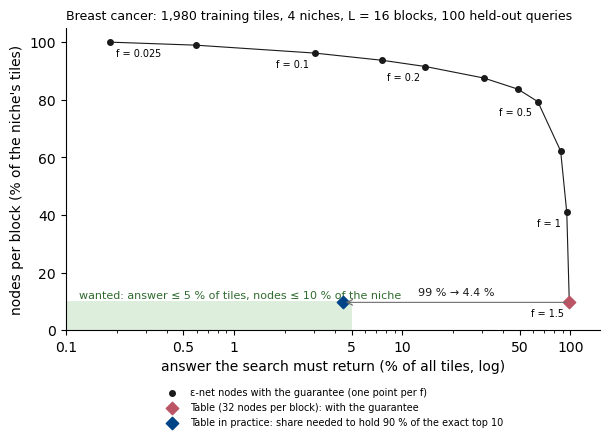

done in 150 s


In [30]:
x = [s["band_pct"] for s in sweep]
y = [s["nodes_pct"] for s in sweep]
fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.add_patch(Rectangle((0.1, 0), 5 - 0.1, 10, color="#DDEEDD", lw=0, zorder=0))
ax.text(0.12, 11, "wanted: answer ≤ 5 % of tiles, nodes ≤ 10 % of the niche", fontsize=8, color="#2E6B2E")
ax.plot(x, y, color="#1A1A1A", lw=0.8, zorder=1)
ax.scatter(x, y, s=16, color="#1A1A1A", zorder=2, label="ε-net nodes with the guarantee (one point per f)")
for s in sweep:
    if s["f"] in (0.025, 0.1, 0.2, 0.5, 1.0, 1.5):
        first = s["f"] == F_GRID[0]
        ax.annotate(f"f = {s['f']:g}", (s["band_pct"], s["nodes_pct"]), xytext=(4, -10) if first else (-4, -10),
                    textcoords="offset points", fontsize=7, ha="left" if first else "right")
ax.scatter([table_band], [table_nodes], s=40, marker="D", color="#BB5566", zorder=3,
           label=f"Table ({K_TABLE} nodes per block): with the guarantee")
ax.scatter([table_needed], [table_nodes], s=40, marker="D", color="#004488", zorder=3,
           label="Table in practice: share needed to hold 90 % of the exact top 10")
ax.annotate("", xy=(table_needed, table_nodes), xytext=(table_band, table_nodes),
            arrowprops=dict(arrowstyle="->", color="#6E6E6E", lw=0.8))
ax.text(np.sqrt(table_needed * table_band), table_nodes + 2.5,
        f"{table_band:.0f} % → {table_needed:.1f} %", ha="center", fontsize=8, color="#1A1A1A")
ax.set_xscale("log")
ax.set_xlim(0.1, 150)
ax.set_ylim(0, 105)
ax.set_xticks([0.1, 0.5, 1, 5, 10, 50, 100])
ax.set_xticklabels(["0.1", "0.5", "1", "5", "10", "50", "100"])
ax.set_xlabel("answer the search must return (% of all tiles, log)")
ax.set_ylabel("nodes per block (% of the niche's tiles)")
ax.set_title(f"Breast cancer: {N:,} training tiles, {N_NICHES} niches, L = {L} blocks, {N_QUERIES} held-out queries",
             fontsize=9, loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=1)
fig.tight_layout()
fig.savefig(REPO / "figures" / "png" / "eps_tradeoff_breast_standalone.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"done in {time.time() - t_start:.0f} s")